**Notebook for an overview and examples**

Project summary :

Next-OSO project consists of improving the current soil occupation OSO product by exploring Deep Learning architectures and Foundation models embedding.

This notebook aims to give an overview of the project and give examples to on how to use the main functions. 

Before going through, read the README.md file. 

## Next-OSO dataset

In [1]:
from data_functions import dataset, plot_functions

# Create Nextoso dataset object
path_to_nextoso_data = "/home/hkerino/Documents/nextoso-dataset/data/10m"
data = dataset.next_oso_Dataset(path_data=path_to_nextoso_data)
print(f"Number of samples in the dataset: {len(data)}")

# Create Nextoso dataset object for a specific fold
data_one_fold = dataset.next_oso_Dataset(path_data=path_to_nextoso_data, folds=[1])
print(f"Number of samples in the dataset: {len(data_one_fold)}")

Number of samples in the dataset: 3598
Number of samples in the dataset: 723


In [2]:
# Load a sample, 2 possibilities: by index or by sample name
sample_1 = data.__getitem__(0)
sample_2 = data.__getitem__("0404")

inputs, labels = sample_1
print(f"inputs list length : {len(inputs)} => (S2, dates, masks, geodatas)\n")

print(f"Labels shape : {labels.shape}\n")

print(
    "Inputs shapes :\n"
    f"sample S2 shape : {inputs[0].shape} # (C,T,H,W)\n"
    f"dates shape     : {inputs[1].shape} # (T)\n"
    f"masks           : {inputs[2]}\n"
    f"geodatas shape  : {inputs[3].shape} # (D, H, W) \n"
)

inputs list length : 4 => (S2, dates, masks, geodatas)

Labels shape : torch.Size([128, 128])

Inputs shapes :
sample S2 shape : torch.Size([10, 54, 128, 128]) # (C,T,H,W)
dates shape     : torch.Size([54]) # (T)
masks           : None
geodatas shape  : torch.Size([4, 128, 128]) # (D, H, W) 



In [3]:
# By default S2 mask is not returned and geodatas is. Can be control
data_new = dataset.next_oso_Dataset(
    path_data=path_to_nextoso_data, use_mnt_data=False, mask_needed=True
)
sample_3 = data_new.__getitem__(0)
print(f"masks     : {sample_3[0][2].shape}\ngeodatas  : {sample_3[0][3]}")

masks     : torch.Size([54, 128, 128])
geodatas  : None


In [4]:
# plots
data_plot = dataset.next_oso_Dataset(
    path_data=path_to_nextoso_data, use_mnt_data=True, mask_needed=True
)

ID = "0053"
inputs, label = data_plot.__getitem__(ID)

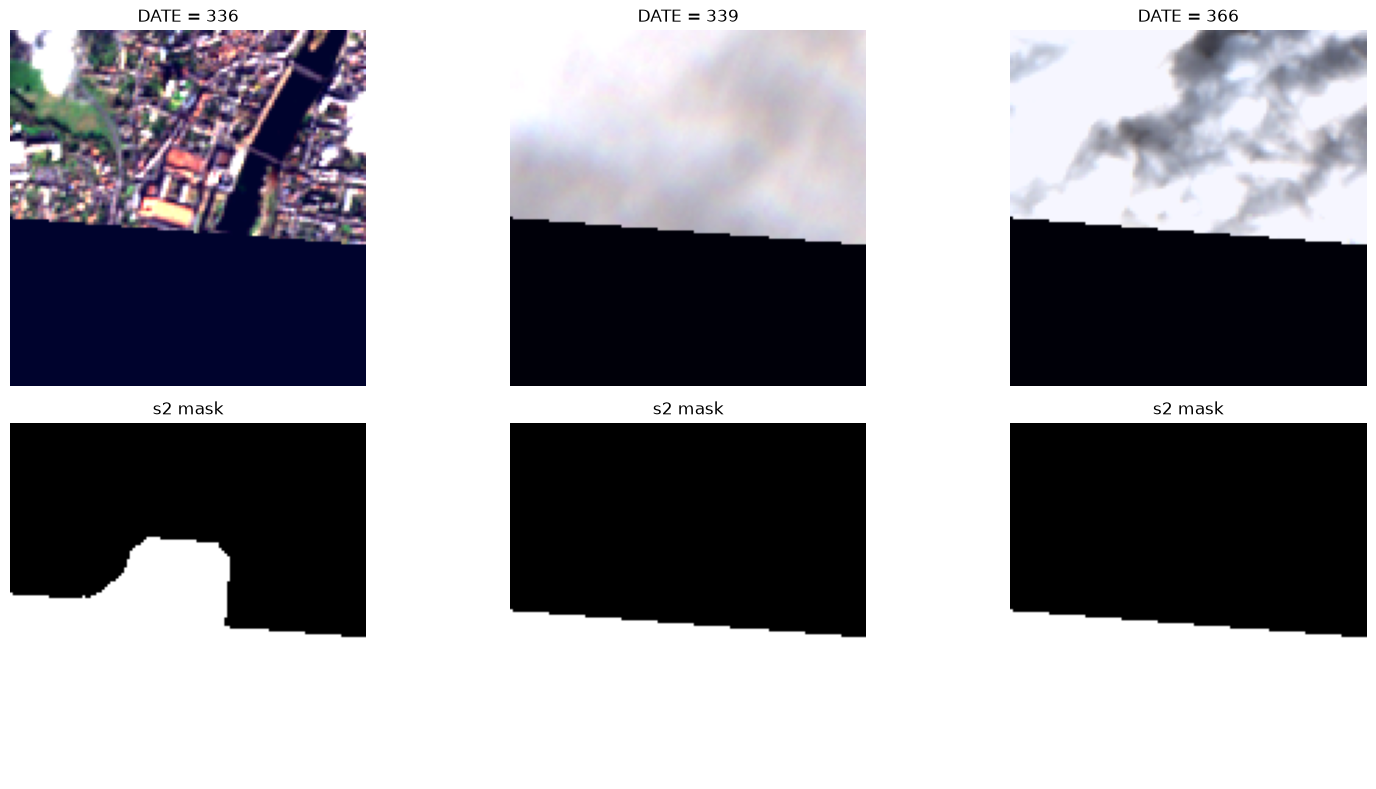

In [5]:
# S2 and masks
plot_functions.plot_s2_and_mask(
    s2=inputs[0], dates=inputs[1], masks=inputs[2], start_timestep=58
)

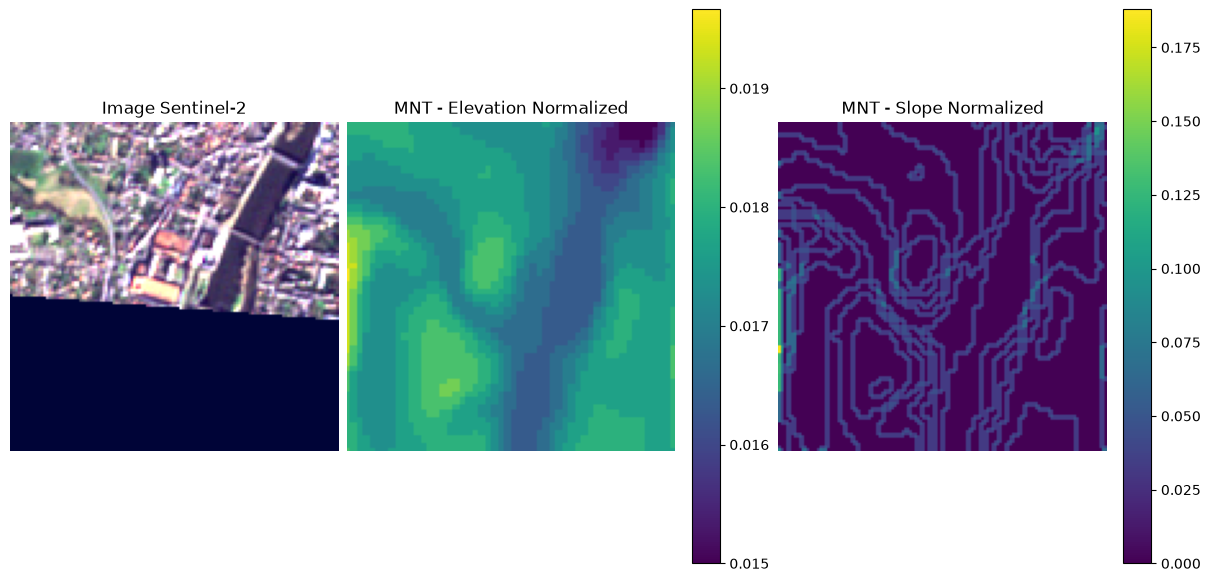

Longitude normalized :tensor([[0.3428, 0.3428, 0.3428,  ..., 0.3428, 0.3428, 0.3428],
        [0.3428, 0.3428, 0.3428,  ..., 0.3428, 0.3428, 0.3428],
        [0.3428, 0.3428, 0.3428,  ..., 0.3428, 0.3428, 0.3428],
        ...,
        [0.3438, 0.3438, 0.3438,  ..., 0.3438, 0.3438, 0.3438],
        [0.3438, 0.3438, 0.3438,  ..., 0.3438, 0.3438, 0.3438],
        [0.3439, 0.3439, 0.3439,  ..., 0.3439, 0.3439, 0.3439]])
Latitude normalized :tensor([[0.5318, 0.5318, 0.5318,  ..., 0.5318, 0.5318, 0.5318],
        [0.5318, 0.5318, 0.5318,  ..., 0.5318, 0.5318, 0.5318],
        [0.5318, 0.5318, 0.5318,  ..., 0.5318, 0.5318, 0.5318],
        ...,
        [0.5308, 0.5308, 0.5308,  ..., 0.5308, 0.5308, 0.5308],
        [0.5308, 0.5308, 0.5308,  ..., 0.5308, 0.5308, 0.5308],
        [0.5308, 0.5308, 0.5308,  ..., 0.5308, 0.5308, 0.5308]])


In [6]:
# Geodatas (slopes and elevation)
plot_functions.plot_geodatas(s2=inputs[0], geodatas=inputs[3], s2_timestep=1)

print(f"Longitude normalized :{inputs[3][0]}\nLatitude normalized :{inputs[3][1]}")

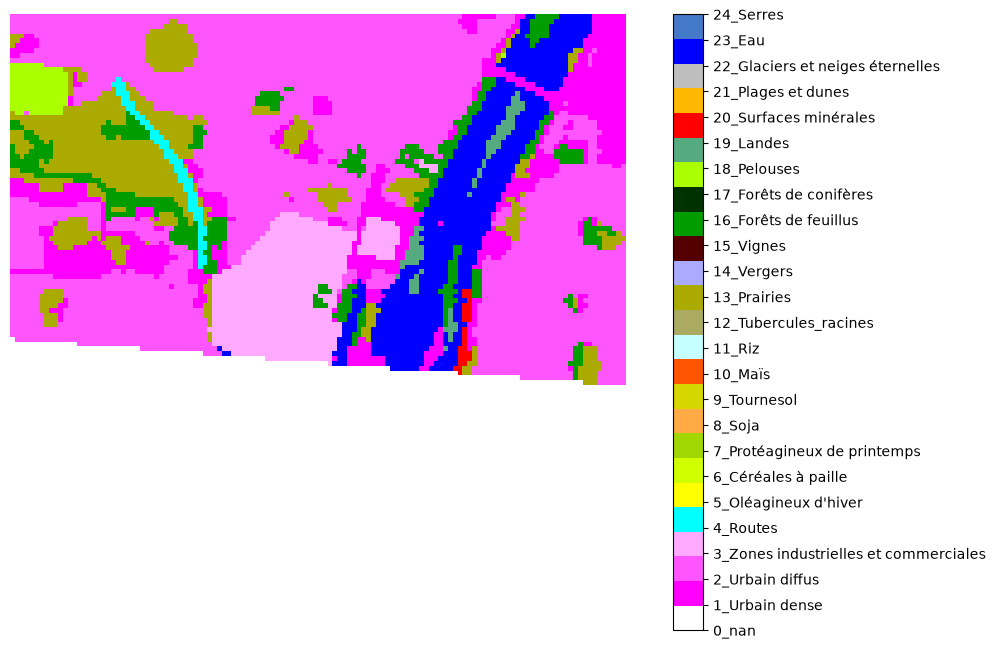

In [7]:
# Label
plot_functions.plot_label(label)

In [8]:
# Label type can be adjusted
data_osotype = dataset.next_oso_Dataset(
    path_data=path_to_nextoso_data, label_type="oso_type"
)
data_probas = dataset.next_oso_Dataset(
    path_data=path_to_nextoso_data, label_type="probas"
)

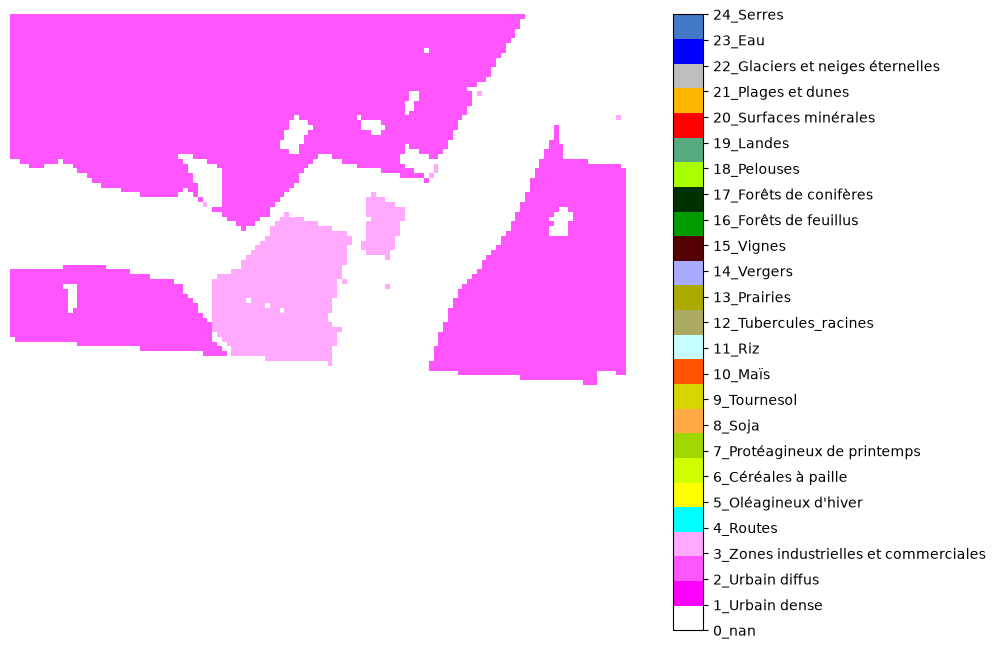

In [9]:
# OSO type label
_, label_oso_type = data_osotype.__getitem__(ID)
plot_functions.plot_label(label_oso_type)

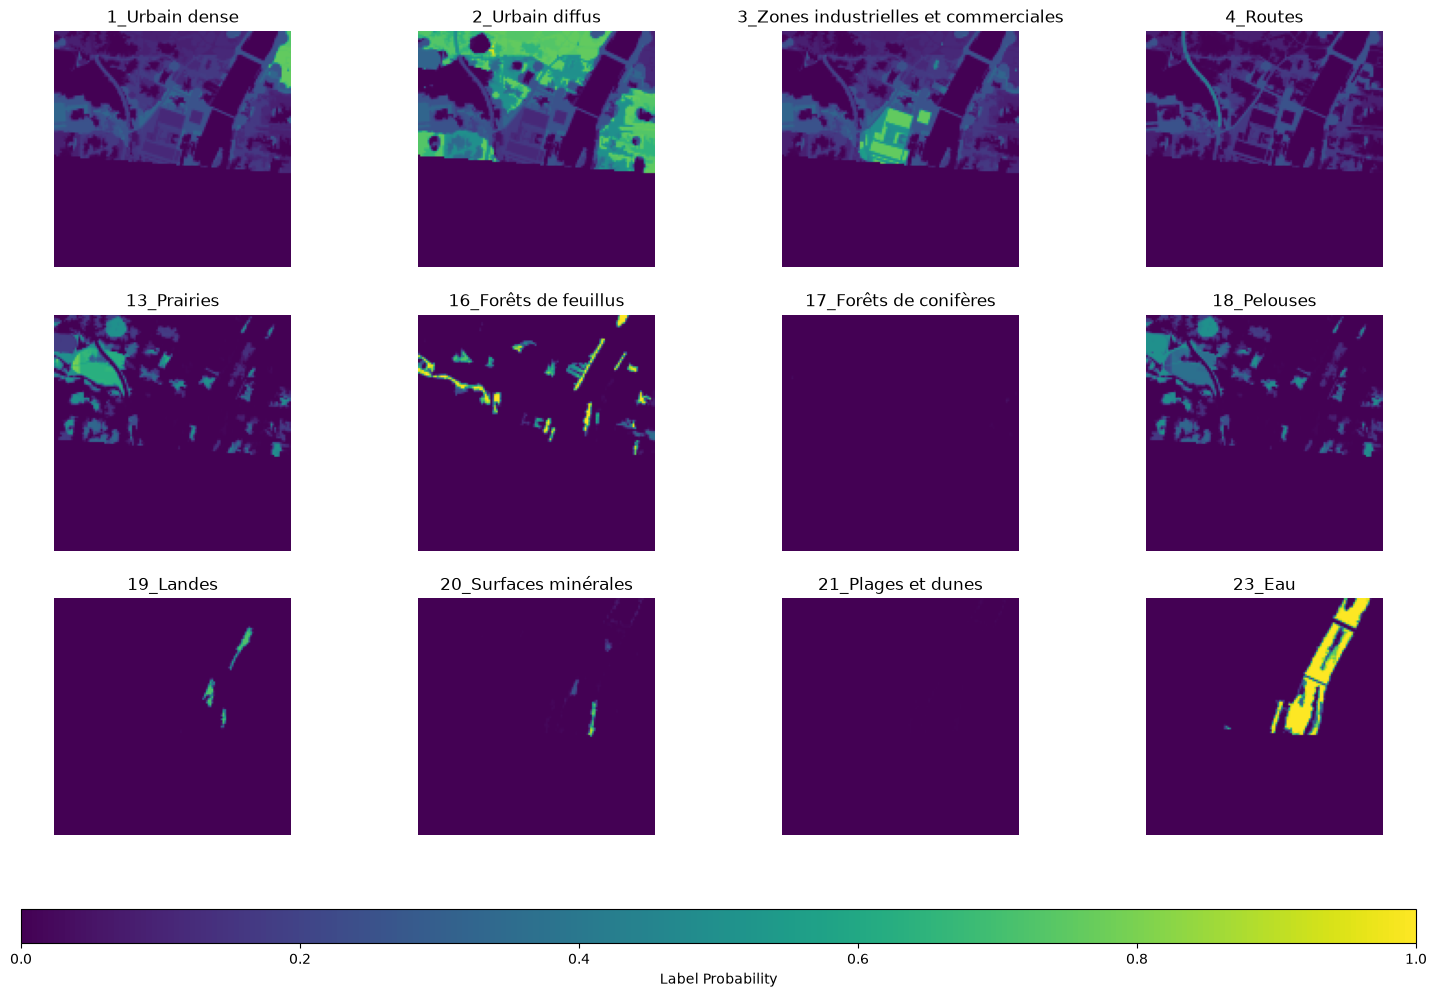

In [10]:
# Probas label
_, label_probas = data_probas.__getitem__(ID)
plot_functions.plot_label_probability(label_probas)

## Supervised models

In [2]:
# Exemple for creating classifier with config files
from mains.main_utils import build_model, load_config, select_criterion
from supervised_models.lightning_module import Classifier

path_config_train = "configs/supervised_models/config_local.yaml"
path_config_model = "configs/supervised_models/LTAE.yaml"

config = load_config(train_cfg_path=path_config_train, model_cfg_path=path_config_model)
(
    encoder,
    decoder,
    batch_size,
) = build_model(config=config)
loss_fn = select_criterion("cross_entropy")

classifier = Classifier(
    encoder=encoder, decoder=decoder, batch_size=batch_size, loss_fn=loss_fn
)

print(config)
print(encoder)
print(decoder)

{'path_data': '/home/hkerino/Documents/nextoso-dataset/data/10m', 'path_logs': '/home/hkerino/Documents/next_oso/logs/light_training', 'label_type': 'oso_type', 'label_type_test': 'max_class', 'use_mnt_data': True, 'num_worker': 21, 'num_class': 25, 'folds': [[[1], [4], [5]], [[2, 3, 4], [5], [1]], [[3, 4, 5], [1], [2]], [[4, 5, 1], [2], [3]], [[5, 1, 2], [3], [4]]], 'decoder_type': 'mlp', 'criterion': 'cross_entropy', 'optimizer_scheduler': 'reduce_on_plateau', 'epochs_max': 1, 'batch_size': 1, 'test_model': True, 'accelerator': 'auto', 'devices': 'auto', 'nodes': 1, 'strategy': 'auto', 'running_on_trex_gpu': False, 'learning_rate': 0.0001, 'logs': False, 'model': 'LTAE', 'mask_need': False, 'encoder': {'input_dim': 10, 'n_head': 16, 'd_k': 8, 'd_model': 128, 'T': 1000, 'return_att': False, 'positional_encoding': True}, 'decoder': {'layers': [132, 64, 25], 'dropout': 0.1}}
LTAE2d(
  (inconv): Conv1d(10, 128, kernel_size=(1,), stride=(1,))
  (positional_encoder): PositionalEncoder()
  

In [3]:
# Load from Checkpoint, config should match with training config
from data_functions import dataset

path_logs = "logs/to_keep/LTAE_2026-10-09"
checkpoint = path_logs + "/fold_1/Checkpoints/epoch=188-step=102249.ckpt"

trained_classifier = Classifier.load_from_checkpoint(
    checkpoint,
    weights_only=True,
    encoder=encoder,
    decoder=decoder,
    loss_fn=loss_fn,
    batch_size=batch_size,
)

# dataloader
path_to_nextoso_data = "/home/hkerino/Documents/nextoso-dataset/data/10m"
_, _, dl_test = dataset.get_loaders(
    path_data=path_to_nextoso_data, folds_test=[5], mask_needed=False
)  # Select fold where model hasn't been trained

In [4]:
# Inference
batch = next(iter(dl_test))

trained_classifier.eval()
preds_batch = trained_classifier.predict_step(batch)

/home/hkerino/Documents/next_oso/.pixi/envs/dev/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


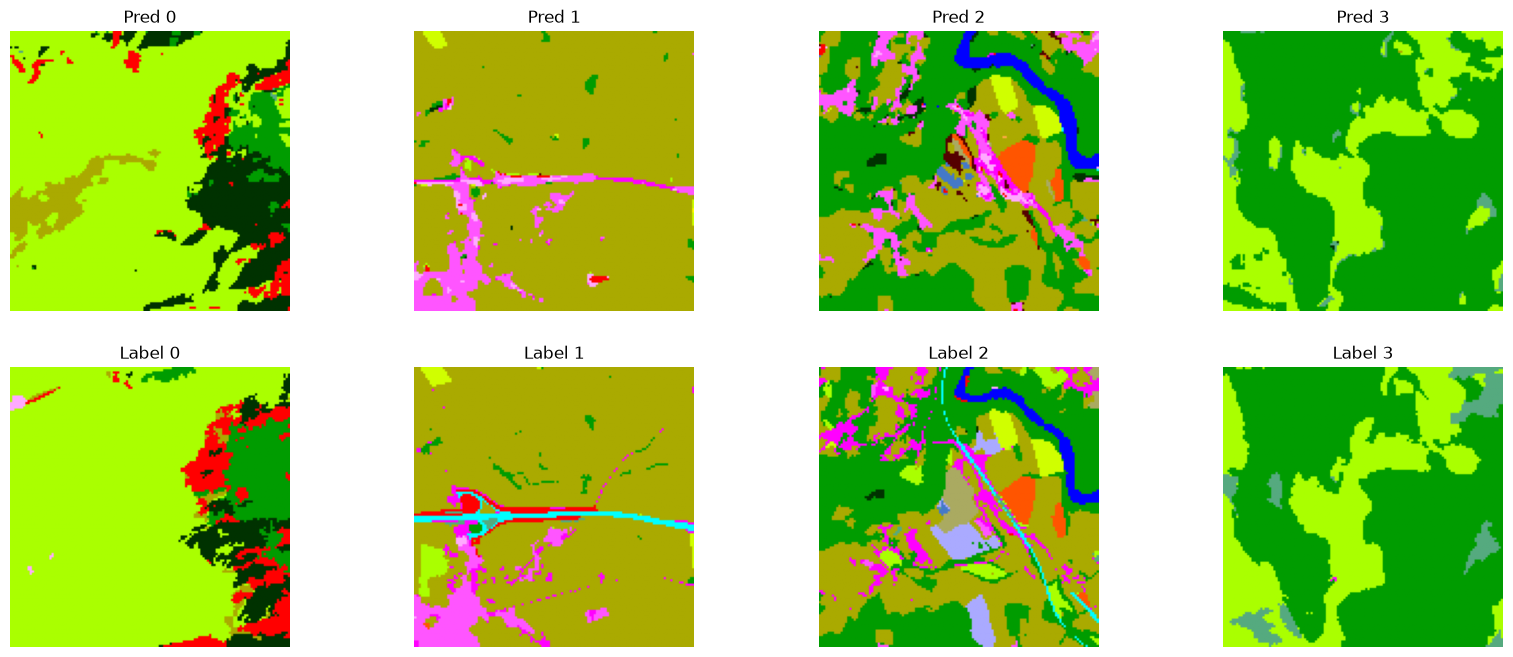

In [5]:
# Plot
from analyse_results import plot_functions_analyse

plot_functions_analyse.plot_preds_and_labels(batch[1], preds_batch)

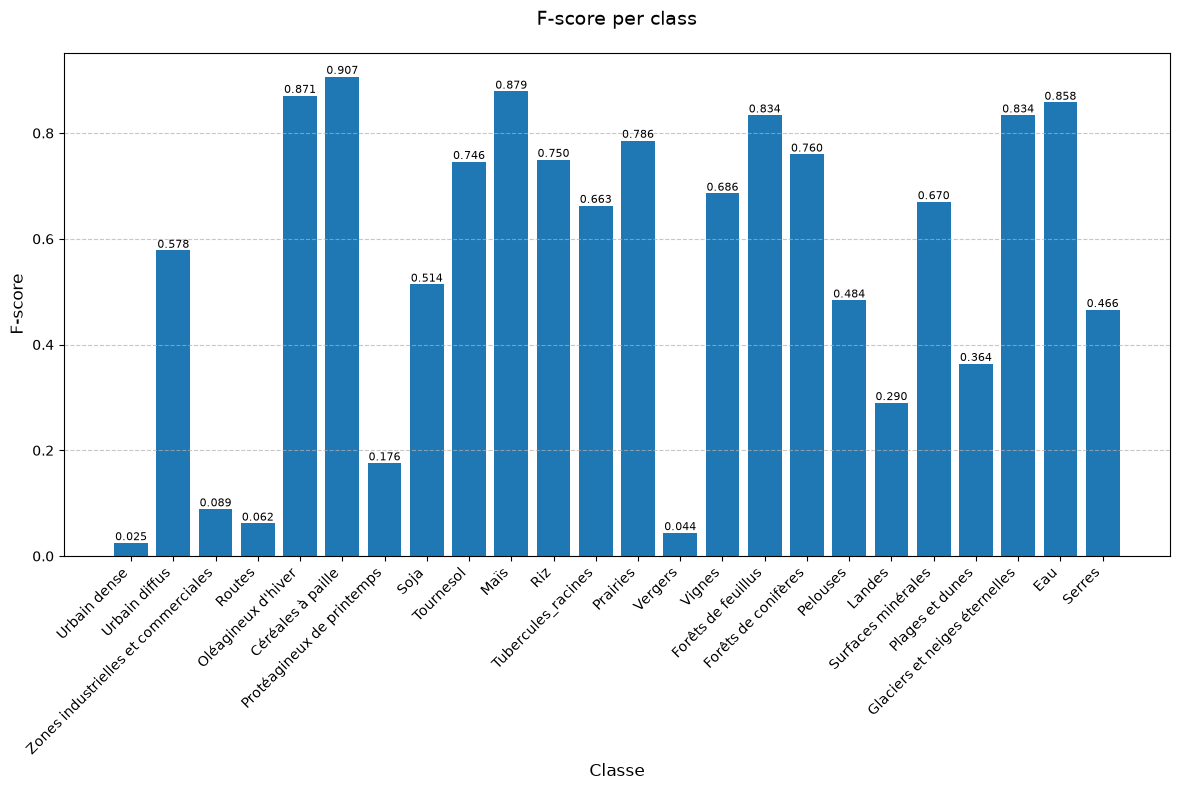

In [6]:
# Plot metric performace of loaded model
from analyse_results import plot_functions_analyse

plot_functions_analyse.plot_fscore_per_class(path_logs=path_logs)

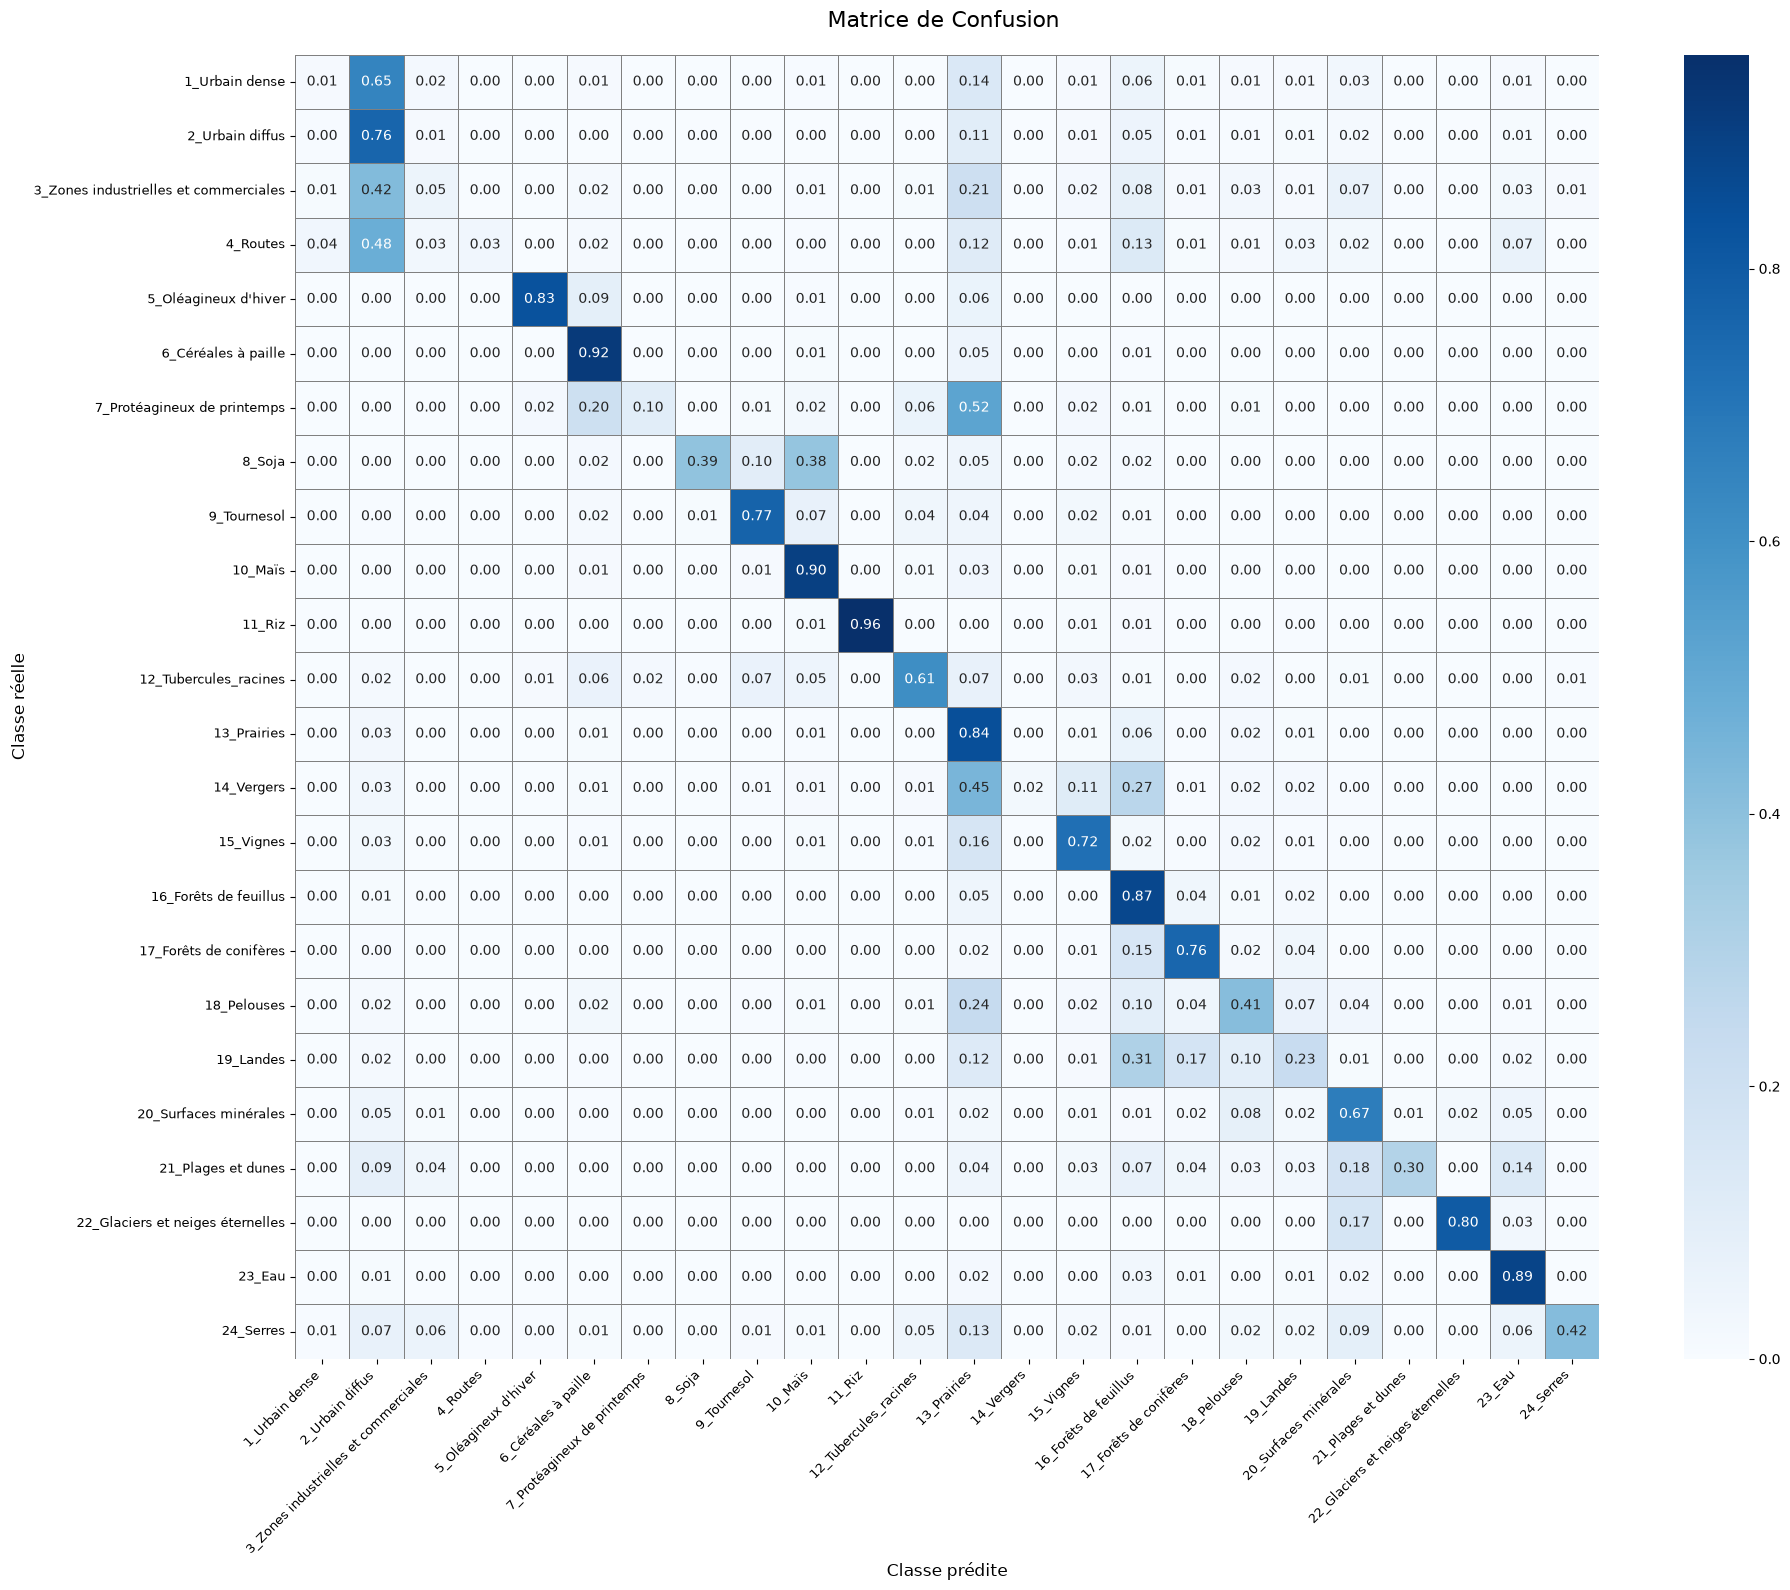

In [7]:
from analyse_results.plot_functions_analyse import plot_confusion_matrix

plot_confusion_matrix(path_logs=path_logs)

## Embedding dataset

In [1]:
# On same idea, embeddings downloaded are available through a torch dataset inhereting from same object
from embedding.dataset_embedding import embedding_dataset
from embedding.plot_functions_embedding import plot_embeddings, plot_embedding

In [2]:
alpha_earth_data = embedding_dataset(model="alpha-earth")
tessera_data = embedding_dataset(model="tessera")
malice_data = embedding_dataset(model="malice")

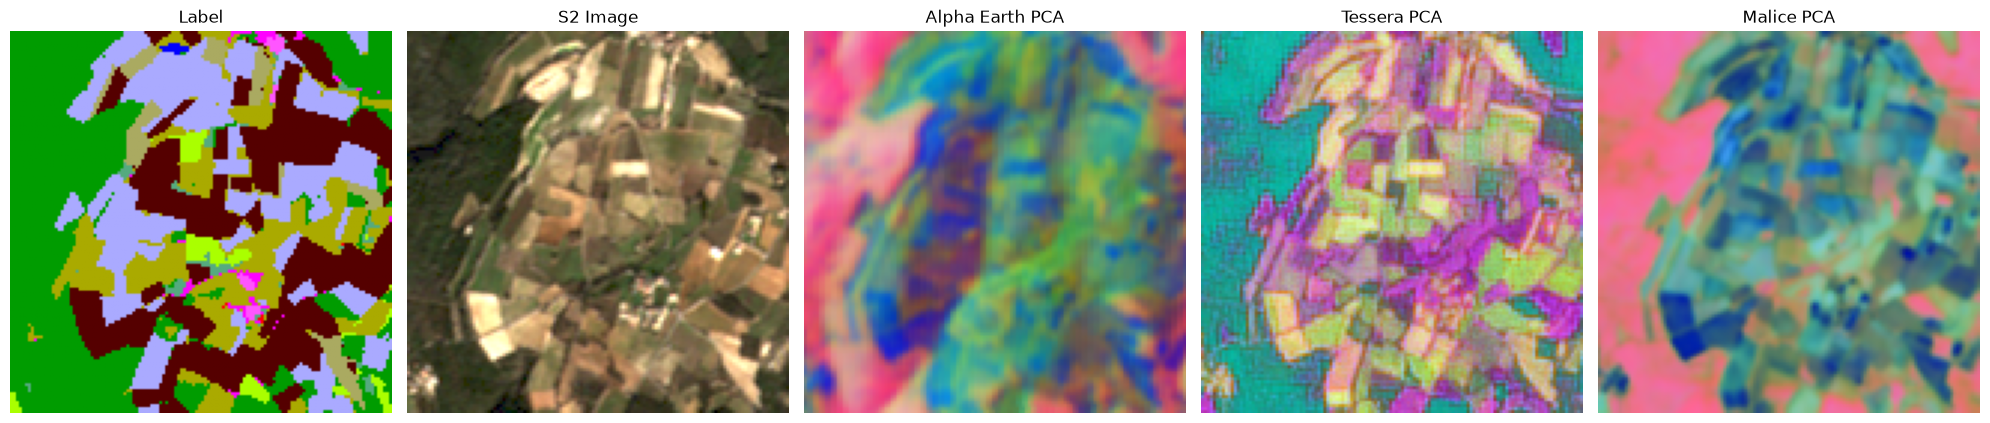

In [ ]:
# Plot all embeddings
plot_embeddings(
    ID="0009",
    alpha_earth_dataset=alpha_earth_data,
    tessera_dataset=tessera_data,
    malice_dataset=malice_data,
    path_data="/home/hkerino/Documents/nextoso-dataset/data/10m",
)

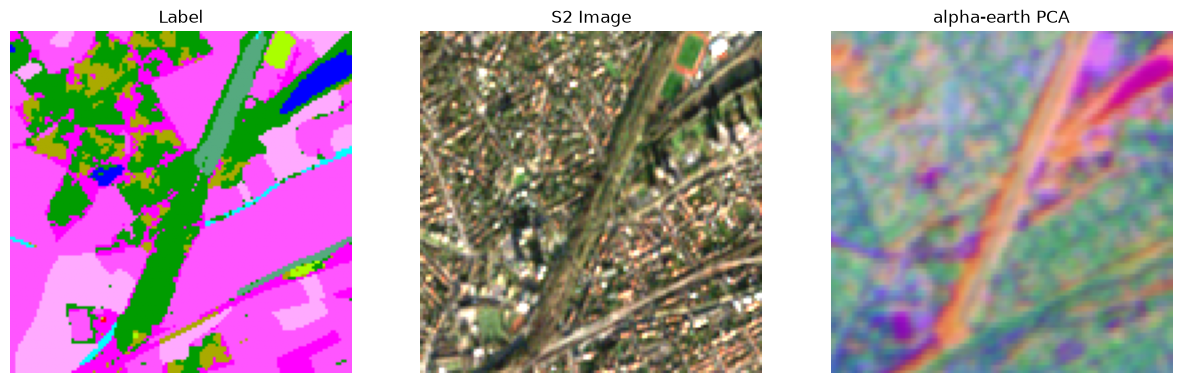

In [6]:
# Plot one embedding
plot_embedding(
    ID="3400",
    emb_data=alpha_earth_data,
    path_data="/home/hkerino/Documents/nextoso-dataset/data/10m",
)

In [16]:
# Works also on pastis
alpha_earth_data_pastis = embedding_dataset(
    dataset="pastis", path_data="/home/hkerino/Documents/PASTIS", model="alpha-earth"
)
tessera_data_pastis = embedding_dataset(
    dataset="pastis", path_data="/home/hkerino/Documents/PASTIS", model="tessera"
)
malice_data_pastis = embedding_dataset(
    dataset="pastis", path_data="/home/hkerino/Documents/PASTIS", model="malice"
)

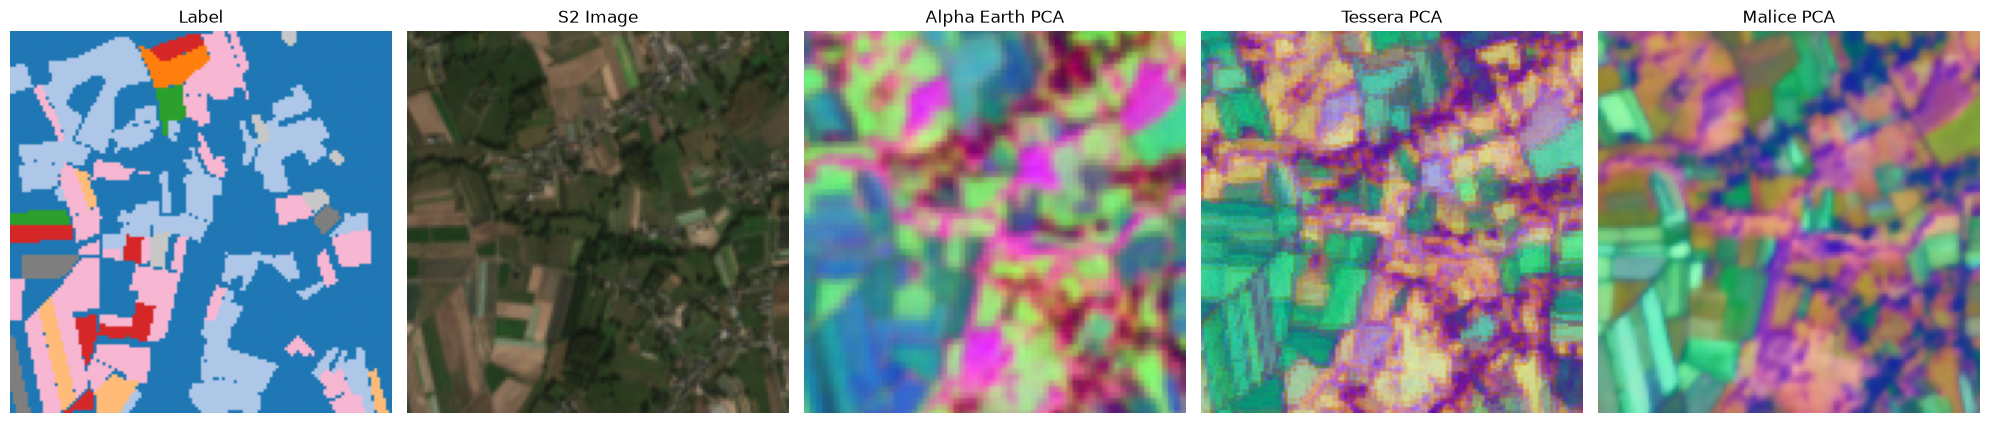

In [17]:
plot_embeddings(
    ID="10001",
    alpha_earth_dataset=alpha_earth_data_pastis,
    tessera_dataset=tessera_data_pastis,
    malice_dataset=malice_data_pastis,
    path_data="/home/hkerino/Documents/PASTIS",
)

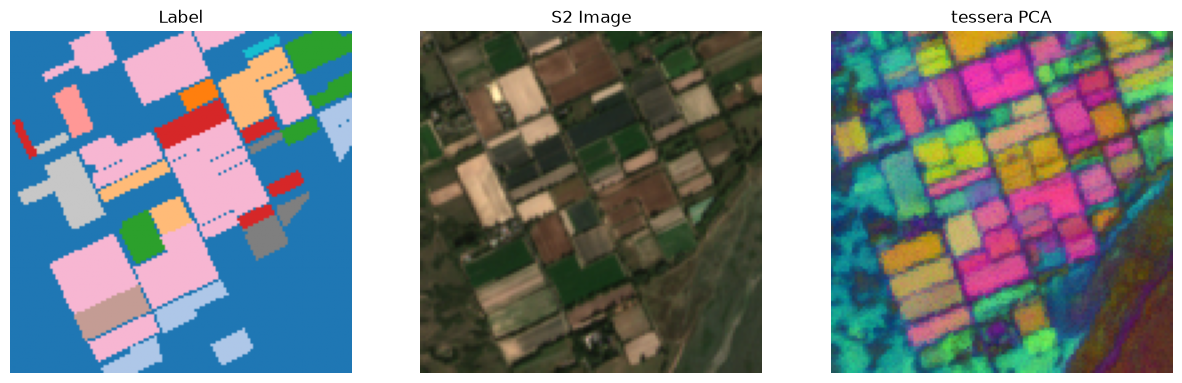

In [18]:
# Plot one embedding
plot_embedding(
    ID="10005", emb_data=tessera_data_pastis, path_data="/home/hkerino/Documents/PASTIS"
)

## Embedding Decoding

In [9]:
# Exemple for creating classifier with config files
import yaml
from mains.main_utils import build_decoder, select_criterion
from embedding.decode_lightning_module import DecodeEmbedding

path_config_train = "configs/embeddings/config_local.yaml"

with open(path_config_train, "r") as f:
    train_cfg = yaml.safe_load(f)
    config_emb = {**train_cfg}

decoder = build_decoder(
    model=config_emb["model"],
    decoder_type=config_emb["decoder_type"],
    dataset=config_emb["dataset"],
    dropout=config_emb["dropout"],
)

classifier = DecodeEmbedding(decoder=decoder, config=config_emb)

print(config_emb)
print(decoder)

{'dataset': 'next_oso', 'model': 'alpha-earth', 'path_data': '/home/hkerino/Documents/nextoso-dataset/data/10m', 'path_logs': '/home/hkerino/Documents/next_oso/fm_logs', 'label_type': 'max_class', 'label_type_test': 'max_class', 'preload_data': False, 'num_worker': 2, 'folds': [[[1], [4], [5]], [[2, 3, 4], [5], [1]], [[3, 4, 5], [1], [2]], [[4, 5, 1], [2], [3]], [[5, 1, 2], [3], [4]]], 'decoder_type': 'mlp', 'batch_size': 4, 'lr': 0.001, 'max_epochs': 1, 'dropout': 0.1}
MLP_Decoder(
  (layer): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=25, bias=True)
  )
  (dropout): Dropout(p=0.1, inplace=False)
)


In [14]:
# Load from Checkpoint, config should match with training config
from embedding.dataset_embedding import embedding_datamodule

path_logs_emb = "logs/alpha-earth/2026-07-22_mlp_kfold"
checkpoint = path_logs_emb + "/fold_1/Checkpoints/epoch=246-step=64961.ckpt"
trained_emb_classifier = DecodeEmbedding.load_from_checkpoint(
    checkpoint, decoder=decoder, config=config_emb
)

# Data for inference
path_to_nextoso_data = "/home/hkerino/Documents/nextoso-dataset/data/10m"
emb_data = embedding_datamodule(
    model="alpha-earth",
    path_data=path_to_nextoso_data,
    fold_test=[5],  # Select fold where model hasn't been trained
    fold_train=[1],
    fold_val=[2],
    batch_size=config_emb["batch_size"],
)

# Load one batch
dl_emb_test = emb_data.test_dataloader()
batch_emb = next(iter(dl_emb_test))

# Inference
trained_emb_classifier.eval()
preds_batch_emb = trained_emb_classifier.predict_step(batch_emb)

/home/hkerino/Documents/next_oso/.pixi/envs/dev/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


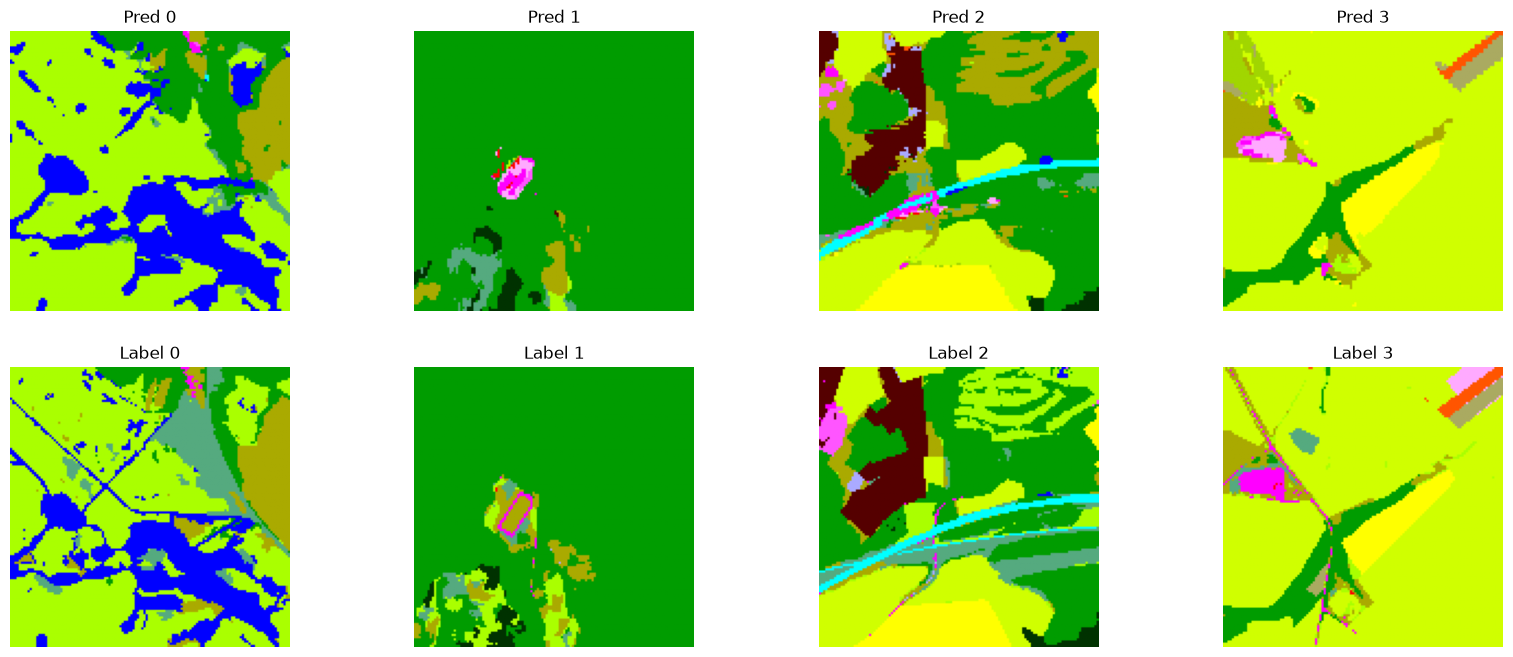

In [15]:
from analyse_results import plot_functions_analyse

plot_functions_analyse.plot_preds_and_labels(batch_emb[1], preds_batch_emb)

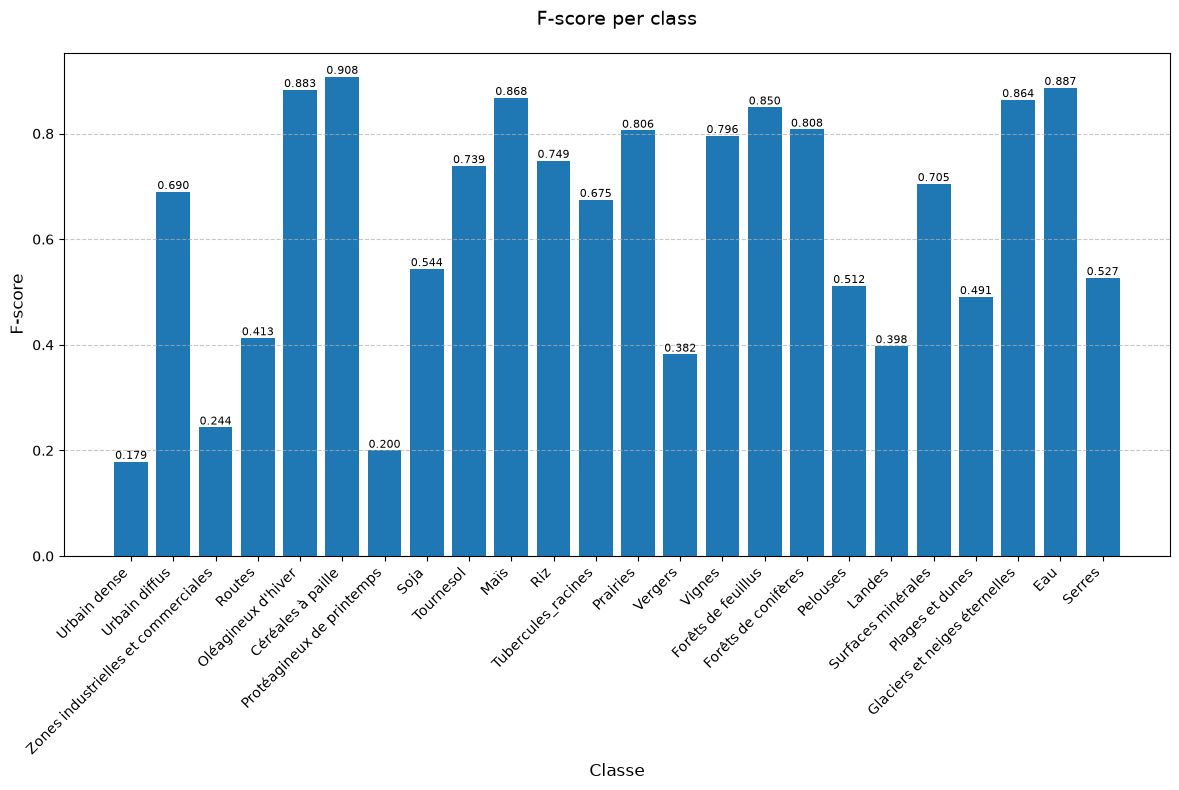

In [16]:
# Plot metric performace of loaded model
plot_functions_analyse.plot_fscore_per_class(path_logs=path_logs_emb)

In [17]:
plot_functions_analyse.plot_confusion_matrix(path_logs=path_logs_emb)

FileNotFoundError: [Errno 2] No such file or directory: 'logs/alpha-earth/2026-07-22_mlp_kfold/fold_1/raw_matrix.pt'